# 05 - Failure analysis: where the baseline breaks on the GSO test set

**WHAT:** which objects fail, how badly, and why. Sections 2 to 6 use the run numbers; section 7 adds the tags from reviewing Steven's 360 videos (seed 0). The write-up for the Drive is `failure-notes-part3.md`. Owner: Hector.
**WHERE:** `notebooks/`. Runs on CPU, no container or GPU needed. Run top to bottom from `notebooks/` or the repo root. Writes figures and tables to `figures/` (not committed; copies go on the Drive `figures/` folder).
**INPUTS:** `results/metrics.csv` (CLIP, Steven's `scripts/eval_clip.py`), `results/baseline_log.csv` (time, VRAM, Gaussian count, mesh size, Steven's `scripts/run_batch.py`), `data/gso_inputs/objects.csv`.
**WHY:** the failure cases are the evidence for choosing the improvement, and for the report's limitations discussion. Notebook 04 has the overall tables; this one looks at the bottom of the ranking.

**Paper limitations to check against (Sec. 5 and App. A.3):** multi-face Janus problem, oversaturated texture, baked lighting, blurry back view. Tag names follow Steven's `failure-notes` Parts 1 and 2.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "figures"          # local only (excluded); upload to the Drive figures/ folder
FIG_DIR.mkdir(exist_ok=True)

BASE_TAG = "gso_baseline"
FACE_CAP = 100_000   # extract_mesh(decimate_target=1e5) in dreamgaussian/gs_renderer.py
pd.set_option("display.precision", 3)

## 1. Load and join (same join as notebook 04)

`metrics.csv` tags these runs `gso_baseline` but `baseline_log.csv` tags them `baseline` (see `CHANGELOG.md`, 2026-11-05), so we keep test-set objects from the log and join on `(name, seed)`. Final meshes only (stage 2).

In [2]:
metrics = pd.read_csv(ROOT / "results/metrics.csv")
log = pd.read_csv(ROOT / "results/baseline_log.csv")
objects = pd.read_csv(ROOT / "data/gso_inputs/objects.csv")
gso_names = set(objects.short_name)

base = metrics[(metrics.tag == BASE_TAG) & (metrics.stage == 2) & (metrics.status == "ok")]
gso_log = log[log.image.isin(gso_names)].rename(columns={"image": "name"})
runs = base.merge(gso_log, on=["name", "seed"], how="left", validate="one_to_one")
assert len(runs) == 42 and runs.total_s.notna().all()

# Same groups as notebook 04, from the objects.csv notes (written before the baseline ran)
GROUPS = {
    "head-on (body hidden)": ["turtle", "shark", "orca"],
    "flat / printed": ["cartridge", "headset_box"],
    "two glossy figurines": ["cats"],
}
group_of = {name: g for g, names in GROUPS.items() for name in names}
runs["group"] = runs.name.map(group_of).fillna("standard")
print(len(runs), "runs,", runs.name.nunique(), "objects")

42 runs, 14 objects


## 2. Stage 2 never changes the geometry

The run log records the mesh after stage 1 (`mesh1_v`, `mesh1_f`) and the final mesh (`final_v`, `final_f`). If they always match, stage 2 only refines the texture, so any shape failure is already locked in at the end of stage 1. That matches the paper (stage 2 is UV-space texture refinement) and Steven's smoke test note in `CHANGELOG.md` (2026-10-28).

In [3]:
same = (runs.mesh1_v == runs.final_v) & (runs.mesh1_f == runs.final_f)
print(f"Stage 1 mesh == final mesh in {same.sum()} of {len(runs)} runs")

Stage 1 mesh == final mesh in 42 of 42 runs


## 3. The worst objects hit the mesh size cap

After marching cubes, `extract_mesh` decimates any mesh with more than 100,000 faces down to 100,000 (`gs_renderer.py`, `decimate_target=1e5`). Decimation can land a face or two under the target, so a run counts as capped at 99,990 faces or more. A capped mesh means the raw surface had **more than** 100k faces before decimation; we can't see how many more.

In [4]:
runs["at_cap"] = runs.final_f >= FACE_CAP - 10

cap_table = runs.groupby("at_cap").clip_sim.agg(["count", "mean", "min", "max"])
cap_table.index = cap_table.index.map({False: "below cap", True: "at cap"})
display(cap_table)

capped = runs[runs.at_cap][["name", "seed", "group", "clip_sim", "final_f", "gaussians_final"]]
capped.sort_values(["name", "seed"])

,count,mean,min,max
at_cap,,,,
below cap,33,0.737,0.594,0.848
at cap,9,0.479,0.402,0.624


,name,seed,group,clip_sim,final_f,gaussians_final
3,cartridge,0,flat / printed,0.437,100000,44352
4,cartridge,1,flat / printed,0.413,100000,49378
5,cartridge,2,flat / printed,0.411,100000,45504
15,headset_box,0,flat / printed,0.407,100000,43631
16,headset_box,1,flat / printed,0.402,99999,44154
17,headset_box,2,flat / printed,0.435,100000,47317
36,turtle,0,head-on (body hidden),0.624,100000,46192
37,turtle,1,head-on (body hidden),0.573,100000,48653
38,turtle,2,head-on (body hidden),0.608,100000,45017


In [5]:
# Per object: how many of the 3 seeds hit the cap
cap_by_obj = (runs.groupby("name")
              .agg(group=("group", "first"), clip_mean=("clip_sim", "mean"),
                   faces_mean=("final_f", "mean"), seeds_at_cap=("at_cap", "sum"))
              .sort_values("clip_mean"))
cap_by_obj

,group,clip_mean,faces_mean,seeds_at_cap
name,,,,
headset_box,flat / printed,0.415,99999.667,3
cartridge,flat / printed,0.420,100000.000,3
turtle,head-on (body hidden),0.602,100000.000,3
orca,head-on (body hidden),0.629,63671.667,0
shark,head-on (body hidden),0.664,70792.667,0
cats,two glossy figurines,0.674,56868.667,0
giraffe,standard,0.691,85634.667,0
android,standard,0.722,77906.667,0
squirrel,standard,0.730,50851.333,0


In [6]:
# For contrast: the authors' 8 sample images (mini-baseline, no CLIP scores)
mini = log[~log.image.isin(gso_names)]
print(f"Mini-baseline: {(mini.final_f >= FACE_CAP - 10).sum()} of {len(mini)} runs at the cap, "
      f"largest mesh {mini.final_f.max():,} faces")

Mini-baseline: 0 of 24 runs at the cap, largest mesh 63,388 faces


## 4. What tracks a low score, across the 14 objects

Spearman rank correlation between each object's mean CLIP and its mean run stats. Rank-based, so one extreme object can't dominate. **Caveats:** only 14 objects, and these are correlations, not causes. Some of these stats move together (a bigger mesh takes longer to texture in stage 2).

In [7]:
per_obj = runs.groupby("name")[
    ["clip_sim", "final_f", "total_s", "stage1_s", "stage2_s", "gaussians_final", "vram_stage1_mib"]
].mean()

rows = []
for col in per_obj.columns.drop("clip_sim"):
    rho, p = spearmanr(per_obj.clip_sim, per_obj[col])
    rows.append({"stat": col, "spearman_rho": rho, "p_value": p})
corr = pd.DataFrame(rows).sort_values("spearman_rho")
corr.to_csv(FIG_DIR / "table_failure_correlations.csv", index=False, float_format="%.4f")
corr

,stat,spearman_rho,p_value
1,total_s,-0.921,2.982e-06
2,stage1_s,-0.895,1.580e-05
0,final_f,-0.871,4.947e-05
3,stage2_s,-0.711,4.325e-03
4,gaussians_final,-0.604,2.206e-02
5,vram_stage1_mib,0.516,5.864e-02


## 5. Figure: mesh size vs CLIP, every run

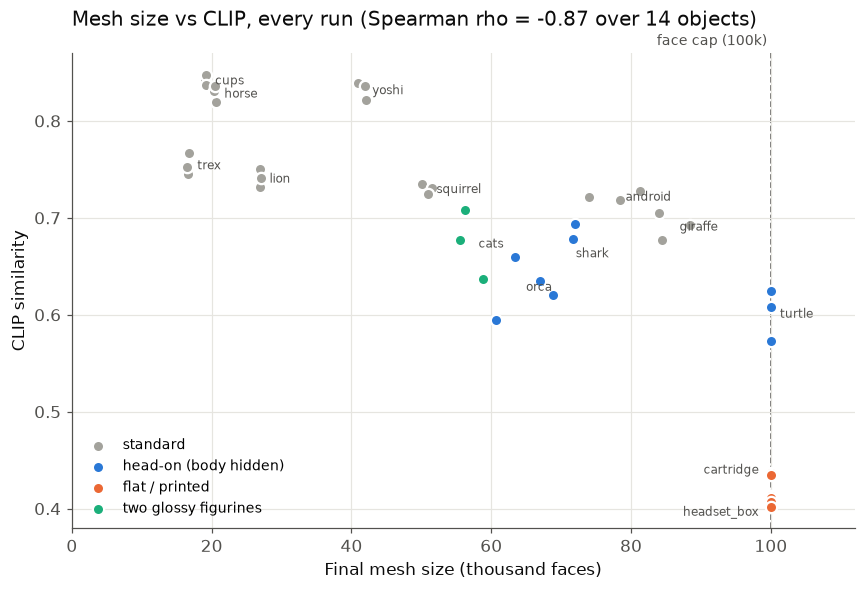

In [8]:
COLORS = {
    "standard": "#a3a29c",
    "head-on (body hidden)": "#2a78d6",
    "flat / printed": "#eb6834",
    "two glossy figurines": "#1baf7a",
}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(8, 5.5))
for group, color in COLORS.items():
    g = runs[runs.group == group]
    ax.scatter(g.final_f / 1000, g.clip_sim, s=55, color=color, edgecolors="white",
               linewidths=1.5, label=group, zorder=3)

ax.axvline(FACE_CAP / 1000, color=MUTED, linestyle="--", linewidth=1, zorder=1)
ax.text(FACE_CAP / 1000, 1.01, "face cap (100k) ", color=MUTED, fontsize=9, ha="right",
        va="bottom", transform=ax.get_xaxis_transform())

# Label each object once, at its mean position (nudge the two that sit on top of each other)
NUDGE = {"cartridge": (-8, 10), "headset_box": (-8, -14)}
for name, r in runs.groupby("name")[["final_f", "clip_sim"]].mean().iterrows():
    dx, dy = NUDGE.get(name, (6, -3))
    ax.annotate(name, (r.final_f / 1000, r.clip_sim), xytext=(dx, dy),
                textcoords="offset points", fontsize=8, color=MUTED,
                ha="right" if name in NUDGE else "left")

rho = corr.set_index("stat").loc["final_f", "spearman_rho"]
ax.set_xlabel("Final mesh size (thousand faces)")
ax.set_ylabel("CLIP similarity")
ax.set_xlim(0, 112)
ax.set_title(f"Mesh size vs CLIP, every run (Spearman rho = {rho:.2f} over 14 objects)",
             loc="left", color=INK, pad=18)
ax.grid(color="#e6e5e0", zorder=0)
ax.legend(loc="lower left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_mesh_size_vs_clip.png", bbox_inches="tight")
plt.show()

## 6. Worst run per object

In [9]:
worst = (runs.loc[runs.groupby("name").clip_sim.idxmin(),
                  ["name", "group", "seed", "clip_sim", "final_f", "at_cap"]]
         .sort_values("clip_sim"))
worst.to_csv(FIG_DIR / "table_worst_run_per_object.csv", index=False, float_format="%.4f")
worst

,name,group,seed,clip_sim,final_f,at_cap
16,headset_box,flat / printed,1,0.402,99999,True
5,cartridge,flat / printed,2,0.411,100000,True
37,turtle,head-on (body hidden),1,0.573,100000,True
24,orca,head-on (body hidden),0,0.594,60649,False
29,shark,head-on (body hidden),2,0.621,68770,False
8,cats,two glossy figurines,2,0.637,58802,False
13,giraffe,standard,1,0.677,84424,False
2,android,standard,2,0.718,78438,False
32,squirrel,standard,2,0.725,51014,False
21,lion,standard,0,0.732,26936,False


## 7. Failure catalog: tags from the 360 videos

Tags use Steven's categories from `failure-notes` Parts 1 and 2 (THIN, FUSE, ARC, SOLID, STRETCH, ASYM, BLUR, COLOR, HALL, JAG, JANUS, SYM, LEAK), plus MISS (hidden part never built, new in Part 3). Written up per object in `failure-notes-part3.md` (Drive).

**Seed 0 only:** tagged from the input next to the 8 eval angles of each `<name>_s0.mp4`, checked by eye on every video (Hector, Nov 9), with shape calls checked against GSO's photos of the real object. A flaw counts only if it repeats on all 3 seeds (Part 2), so these are still to be confirmed on s1 and s2. `SYM` here means the far side is a mirror copy and that is correct for the object.

Rough link to the paper's limitations (Sec. 5, A.3): JANUS = multi-face Janus problem, BLUR = blurry back view, COLOR = oversaturated texture / baked lighting.

In [10]:
TAGS_S0 = {   # entered by hand from the video review (Nov 9), see failure-notes-part3.md
    "headset_box": "STRETCH COLOR HALL JAG BLUR",
    "cartridge":   "STRETCH JAG COLOR",
    "turtle":      "STRETCH FUSE JAG BLUR",
    "orca":        "COLOR STRETCH BLUR",
    "shark":       "STRETCH MISS JAG BLUR",
    "cats":        "HALL BLUR",
    "giraffe":     "JAG BLUR MISS",
    "android":     "STRETCH BLUR SYM",
    "squirrel":    "MISS THIN",
    "lion":        "SYM BLUR",
    "trex":        "SYM COLOR BLUR",
    "horse":       "SYM BLUR",
    "yoshi":       "MISS BLUR",
    "cups":        "JAG",
}
assert set(TAGS_S0) == gso_names

catalog = cap_by_obj[["group", "clip_mean", "seeds_at_cap"]].copy()
catalog["tags_s0"] = catalog.index.map(TAGS_S0)
catalog.to_csv(FIG_DIR / "table_failure_catalog.csv", float_format="%.4f")
catalog

,group,clip_mean,seeds_at_cap,tags_s0
name,,,,
headset_box,flat / printed,0.415,3,STRETCH COLOR HALL JAG BLUR
cartridge,flat / printed,0.420,3,STRETCH JAG COLOR
turtle,head-on (body hidden),0.602,3,STRETCH FUSE JAG BLUR
orca,head-on (body hidden),0.629,0,COLOR STRETCH BLUR
shark,head-on (body hidden),0.664,0,STRETCH MISS JAG BLUR
cats,two glossy figurines,0.674,0,HALL BLUR
giraffe,standard,0.691,0,JAG BLUR MISS
android,standard,0.722,0,STRETCH BLUR SYM
squirrel,standard,0.730,0,MISS THIN


In [11]:
# How often each tag shows up, and in which part of the ranking
tag_rows = [(name, tag) for name, tags in TAGS_S0.items() for tag in tags.split()]
tagged = pd.DataFrame(tag_rows, columns=["name", "tag"]).merge(
    catalog[["group"]], left_on="name", right_index=True)
tag_counts = (tagged.assign(hard_case=tagged.group != "standard")
              .groupby("tag")
              .agg(objects=("name", "nunique"), in_hard_cases=("hard_case", "sum"))
              .sort_values(["objects", "in_hard_cases"], ascending=False))
tag_counts

,objects,in_hard_cases
tag,,
BLUR,11,5
STRETCH,6,5
JAG,6,4
COLOR,4,3
MISS,4,1
SYM,4,0
HALL,2,2
FUSE,1,1
THIN,1,0


## 8. A human check next to CLIP

**Usable angles (out of 8):** Hector's verdict from each seed 0 video, counting the 8 eval angles (0 to 315) that look clean and recognizable, **judged on the render itself**. Missing hidden parts (MISS) are not counted here, since they only show against the real object.

This is one person on one seed, so treat it as a sanity check on CLIP, not a second metric.

In [12]:
USABLE_ANGLES = {   # Hector, Nov 9, from the s0 videos
    "cartridge": 1, "headset_box": 1, "orca": 1, "turtle": 1,
    "trex": 3, "lion": 4, "yoshi": 3, "cats": 6,   # cats: angles scored 7/10 or higher (90 and 270 were 6/10)
    "shark": 8, "squirrel": 8, "giraffe": 8, "android": 8, "horse": 8, "cups": 8,
}
assert set(USABLE_ANGLES) == gso_names

catalog["usable_angles"] = catalog.index.map(USABLE_ANGLES)
catalog.to_csv(FIG_DIR / "table_failure_catalog.csv", float_format="%.4f")
h_rho, h_p = spearmanr(catalog.clip_mean, catalog.usable_angles)
print(f"CLIP vs usable angles: Spearman rho = {h_rho:.2f} (p = {h_p:.3f}, 14 objects)")
catalog[["group", "clip_mean", "usable_angles", "tags_s0"]].sort_values("clip_mean")

CLIP vs usable angles: Spearman rho = 0.56 (p = 0.039, 14 objects)


,group,clip_mean,usable_angles,tags_s0
name,,,,
headset_box,flat / printed,0.415,1,STRETCH COLOR HALL JAG BLUR
cartridge,flat / printed,0.420,1,STRETCH JAG COLOR
turtle,head-on (body hidden),0.602,1,STRETCH FUSE JAG BLUR
orca,head-on (body hidden),0.629,1,COLOR STRETCH BLUR
shark,head-on (body hidden),0.664,8,STRETCH MISS JAG BLUR
cats,two glossy figurines,0.674,6,HALL BLUR
giraffe,standard,0.691,8,JAG BLUR MISS
android,standard,0.722,8,STRETCH BLUR SYM
squirrel,standard,0.730,8,MISS THIN


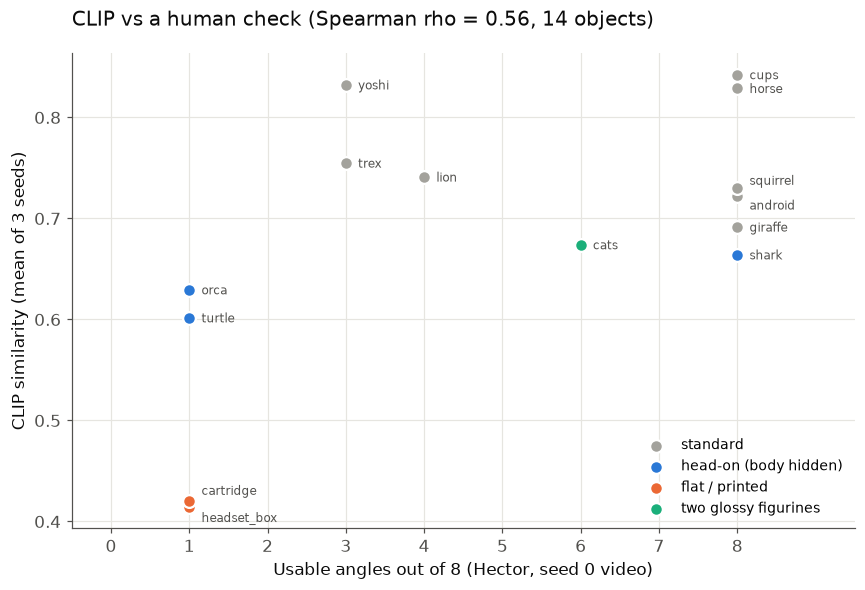

In [13]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for group, color in COLORS.items():
    g = catalog[catalog.group == group]
    ax.scatter(g.usable_angles, g.clip_mean, s=70, color=color, edgecolors="white",
               linewidths=1.5, label=group, zorder=3)

# Label each object; nudge the pairs that sit almost on top of each other
NUDGE = {"cartridge": (8, 4), "headset_box": (8, -10), "squirrel": (8, 2), "android": (8, -9)}
for name, r in catalog.iterrows():
    ax.annotate(name, (r.usable_angles, r.clip_mean), xytext=NUDGE.get(name, (8, -3)),
                textcoords="offset points", fontsize=8, color=MUTED)

ax.set_xticks(range(0, 9))
ax.set_xlim(-0.5, 9.5)
ax.set_xlabel("Usable angles out of 8 (Hector, seed 0 video)")
ax.set_ylabel("CLIP similarity (mean of 3 seeds)")
ax.set_title(f"CLIP vs a human check (Spearman rho = {h_rho:.2f}, 14 objects)",
             loc="left", color=INK, pad=18)
ax.grid(color="#e6e5e0", zorder=0)
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_clip_vs_human.png", bbox_inches="tight")
plt.show()

## 9. Draft findings (check before using)

Printed from the tables above so the text can't drift from the data.

In [14]:
n_cap = runs.at_cap.sum()
capped_objs = sorted(runs[runs.at_cap].name.unique())
below = runs[~runs.at_cap].clip_sim.mean()
print(f"- Stage 2 never changed the mesh ({same.sum()}/{len(runs)} runs): geometry failures are set in stage 1.")
print(f"- {n_cap} of {len(runs)} runs hit the {FACE_CAP:,}-face cap, all from {', '.join(capped_objs)}; "
      f"they average CLIP {runs[runs.at_cap].clip_sim.mean():.3f} vs {below:.3f} for the rest.")
print(f"- Across the 14 objects, mesh size and CLIP have Spearman rho {rho:.2f} "
      f"(run time: {corr.set_index('stat').loc['total_s', 'spearman_rho']:.2f}). Small sample, correlation only.")
print(f"- The authors' 8 sample images never come near the cap (largest mesh {mini.final_f.max():,} faces): "
      f"our hard cases expose a failure their demo set does not.")
both_bad = catalog[(catalog.usable_angles <= 1)].index.tolist()
clip_high_human_low = catalog[(catalog.clip_mean > 0.73) & (catalog.usable_angles <= 4)].index.tolist()
print(f"- CLIP and a human check agree on the collapses ({', '.join(both_bad)}: 0 to 1 usable angles), "
      f"but not in the middle: {', '.join(clip_high_human_low)} score above 0.73 with half or fewer usable angles "
      f"(Spearman rho {h_rho:.2f}).")

- Stage 2 never changed the mesh (42/42 runs): geometry failures are set in stage 1.
- 9 of 42 runs hit the 100,000-face cap, all from cartridge, headset_box, turtle; they average CLIP 0.479 vs 0.737 for the rest.
- Across the 14 objects, mesh size and CLIP have Spearman rho -0.87 (run time: -0.92). Small sample, correlation only.
- The authors' 8 sample images never come near the cap (largest mesh 63,388 faces): our hard cases expose a failure their demo set does not.
- CLIP and a human check agree on the collapses (headset_box, cartridge, turtle, orca: 0 to 1 usable angles), but not in the middle: lion, trex, yoshi score above 0.73 with half or fewer usable angles (Spearman rho 0.56).
